# Notebook 04 — Pandas: De Excel a Datos Industriales y Limpieza Real
**Pungo Academy · Python y Ciencia de Datos Industrial desde Cero en Google Colab**

## Objetivo
Reemplazar tareas manuales repetitivas en Excel por flujos reproducibles en **Pandas**:
1. Cargar una bitácora operativa realista con problemas reales (`726` filas con duplicados, `NaN`s y picos imposibles).
2. Dominar el equivalente en Python de **AutoFiltro**, **Buscar errores** y **Tablas Dinámicas (`.groupby`)**.
3. Ejecutar un pipeline profesional de limpieza (sin sobrescribir datos crudos) y validar antes vs. después.
4. Conectar también con las `9,568` filas reales de la Central Térmica CCPP.
5. **Error Lab 04**: `KeyError` en columnas de DataFrame + reto **Tu Turno**.

In [1]:
# 1. Importación y carga de la bitácora de planta multi-turno
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (11.5, 5.5)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

URL_PLANTA = "https://d29ikw7e1z6k4e.cloudfront.net/curso_python_cero/curso_python_cero_planta_turnos.csv"
URL_CCPP = "https://d29ikw7e1z6k4e.cloudfront.net/curso_python_cero/curso_python_cero_ccpp.csv"

df_raw = pd.read_csv(URL_PLANTA)
print("Dimensiones crudas (filas, columnas):", df_raw.shape)
print("Columnas:", list(df_raw.columns))
df_raw.head(6)

Dimensiones crudas (filas, columnas): (726, 9)
Columnas: ['timestamp', 'equipo', 'turno', 'temperatura_c', 'presion_bar', 'flujo_m3h', 'potencia_kw', 'vibracion_mms', 'estado_operacion']


,timestamp,equipo,turno,temperatura_c,presion_bar,flujo_m3h,potencia_kw,vibracion_mms,estado_operacion
0,2026-03-01 00:00:00,BOM-02,Noche,70.89,16.90,126.56,127.71,3.53,Advertencia
1,2026-03-01 00:00:00,CAL-01,Noche,188.88,11.27,49.85,225.73,1.77,Normal
2,2026-03-01 00:00:00,COM-01,Noche,92.73,8.45,70.82,177.66,3.42,Advertencia
3,2026-03-01 00:00:00,TUR-01,Noche,301.53,29.17,95.72,981.64,3.00,Normal
4,2026-03-01 04:00:00,BOM-02,Noche,76.19,15.83,121.65,110.24,3.62,Alarma
5,2026-03-01 04:00:00,CAL-01,Noche,186.18,11.52,51.65,210.40,2.46,Normal


## Paso 2 — Exploración Rápida e Indexado (AutoFiltro en Pandas)
Con `.info()`, `.describe()` y filtros booleanos (`df[condición]`) diagnosticamos cualquier tabla en dos segundos.

In [2]:
# 2. Diagnóstico estructural y filtros operativos (equivalente a AutoFiltro de Excel)
print("--- Estructura del DataFrame (.info) ---")
df_raw.info()

print("\n--- Conteo de registros por equipo ---")
print(df_raw["equipo"].value_counts())

print("\n--- Filtrar lecturas de TUR-01 en turno Noche con vibración >= 4.0 mm/s ---")
filtro_critico = df_raw[
    (df_raw["equipo"] == "TUR-01")
    & (df_raw["turno"] == "Noche")
    & (df_raw["vibracion_mms"] >= 4.0)
]
print(f"Registros críticos encontrados: {len(filtro_critico)}")
filtro_critico[["timestamp", "equipo", "turno", "temperatura_c", "vibracion_mms", "estado_operacion"]].head(5)

--- Estructura del DataFrame (.info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 726 entries, 0 to 725
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   timestamp         726 non-null    object 
 1   equipo            726 non-null    object 
 2   turno             726 non-null    object 
 3   temperatura_c     702 non-null    float64
 4   presion_bar       711 non-null    float64
 5   flujo_m3h         726 non-null    float64
 6   potencia_kw       726 non-null    float64
 7   vibracion_mms     726 non-null    float64
 8   estado_operacion  726 non-null    object 
dtypes: float64(5), object(4)
memory usage: 51.2+ KB

--- Conteo de registros por equipo ---
equipo
BOM-02    182
TUR-01    182
CAL-01    181
COM-01    181
Name: count, dtype: int64

--- Filtrar lecturas de TUR-01 en turno Noche con vibración >= 4.0 mm/s ---
Registros críticos encontrados: 12


,timestamp,equipo,turno,temperatura_c,vibracion_mms,estado_operacion
75,2026-03-04 00:00:00,TUR-01,Noche,330.76,4.10,Advertencia
172,2026-03-08 00:00:00,TUR-01,Noche,319.04,4.18,Advertencia
224,2026-03-10 04:00:00,TUR-01,Noche,322.56,4.10,Advertencia
268,2026-03-12 00:00:00,TUR-01,Noche,325.36,4.03,Advertencia
340,2026-03-15 00:00:00,TUR-01,Noche,321.92,4.12,Advertencia


## Paso 3 — Auditoría de Calidad: Duplicados, Faltantes (`NaN`) y Picos Físicos
Antes de calcular promedios o entrenar modelos, auditamos los tres enemigos silenciosos de los datos de planta:
1. **Filas duplicadas** por reintentos de comunicación OPC-UA.
2. **Valores faltantes (`NaN`)** por caídas temporales de sensores.
3. **Valores físicamente imposibles** (ej. `999 °C` o `-12 bar` por falla de transmisor 4–20 mA).

Filas duplicadas exactas       : 6
Nulos en temperatura_c         : 24
Nulos en presion_bar           : 15
Picos imposibles temperatura_c : 4 -> valores: [-99.0, 950.0, 999.0, 999.0]
Picos imposibles presion_bar   : 4 -> valores: [-12.0, -8.5, -5.0, 199.0]


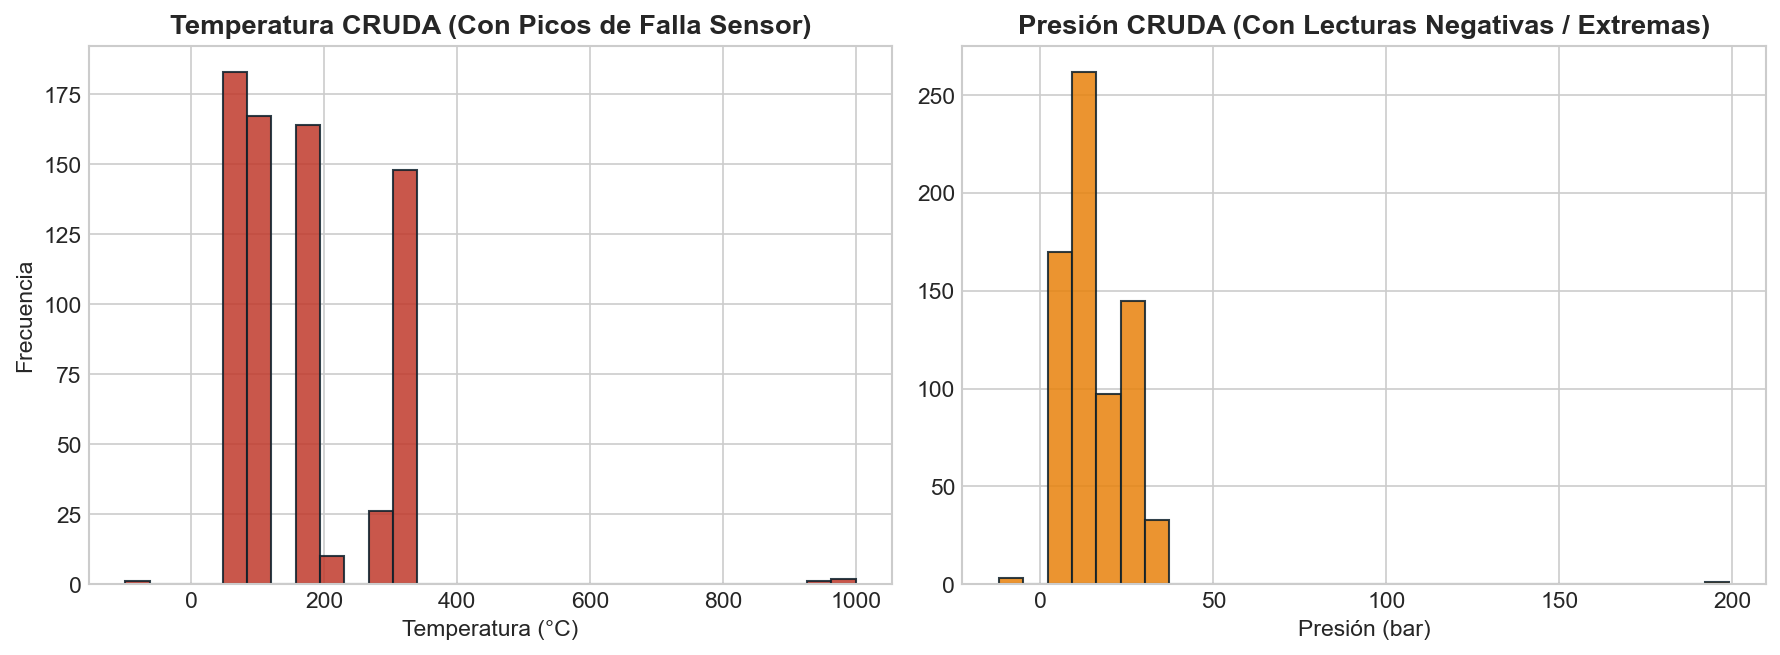

In [3]:
# 3. Cuantificar exactamente los problemas de calidad en df_raw
n_duplicados = int(df_raw.duplicated().sum())
nulos_por_col = df_raw.isnull().sum()
picos_temp = df_raw[(df_raw["temperatura_c"] > 500) | (df_raw["temperatura_c"] < 0)]
picos_pres = df_raw[(df_raw["presion_bar"] < 0) | (df_raw["presion_bar"] > 60)]

print(f"Filas duplicadas exactas       : {n_duplicados}")
print(f"Nulos en temperatura_c         : {int(nulos_por_col['temperatura_c'])}")
print(f"Nulos en presion_bar           : {int(nulos_por_col['presion_bar'])}")
print(f"Picos imposibles temperatura_c : {len(picos_temp)} -> valores: {picos_temp['temperatura_c'].tolist()}")
print(f"Picos imposibles presion_bar   : {len(picos_pres)} -> valores: {picos_pres['presion_bar'].tolist()}")

# Gráfico diagnóstico antes de limpiar
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(df_raw["temperatura_c"].dropna(), bins=30, color=PUNGO_RED, edgecolor=PUNGO_NAVY, alpha=0.85)
axes[0].set_title("Temperatura CRUDA (Con Picos de Falla Sensor)")
axes[0].set_xlabel("Temperatura (°C)")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(df_raw["presion_bar"].dropna(), bins=30, color=PUNGO_AMBER, edgecolor=PUNGO_NAVY, alpha=0.85)
axes[1].set_title("Presión CRUDA (Con Lecturas Negativas / Extremas)")
axes[1].set_xlabel("Presión (bar)")
plt.tight_layout()
plt.show()

## Paso 4 — Pipeline Reproducible de Limpieza (Trabajando en `.copy()`)
Regla de oro industrial: **nunca modifiques los datos crudos sin copiarlos primero** (`df = df_raw.copy()`). Además, en lugar de rellenar toda la planta con un promedio global, imputamos cada `NaN` con la **mediana de su propio equipo** (`groupby("equipo").transform("median")`).

Filas después de limpiar: 720
Total de nulos restantes: 0
Rango limpio temperatura_c: 54.8 a 339.4 °C
Rango limpio presion_bar  : 7.4 a 33.1 bar


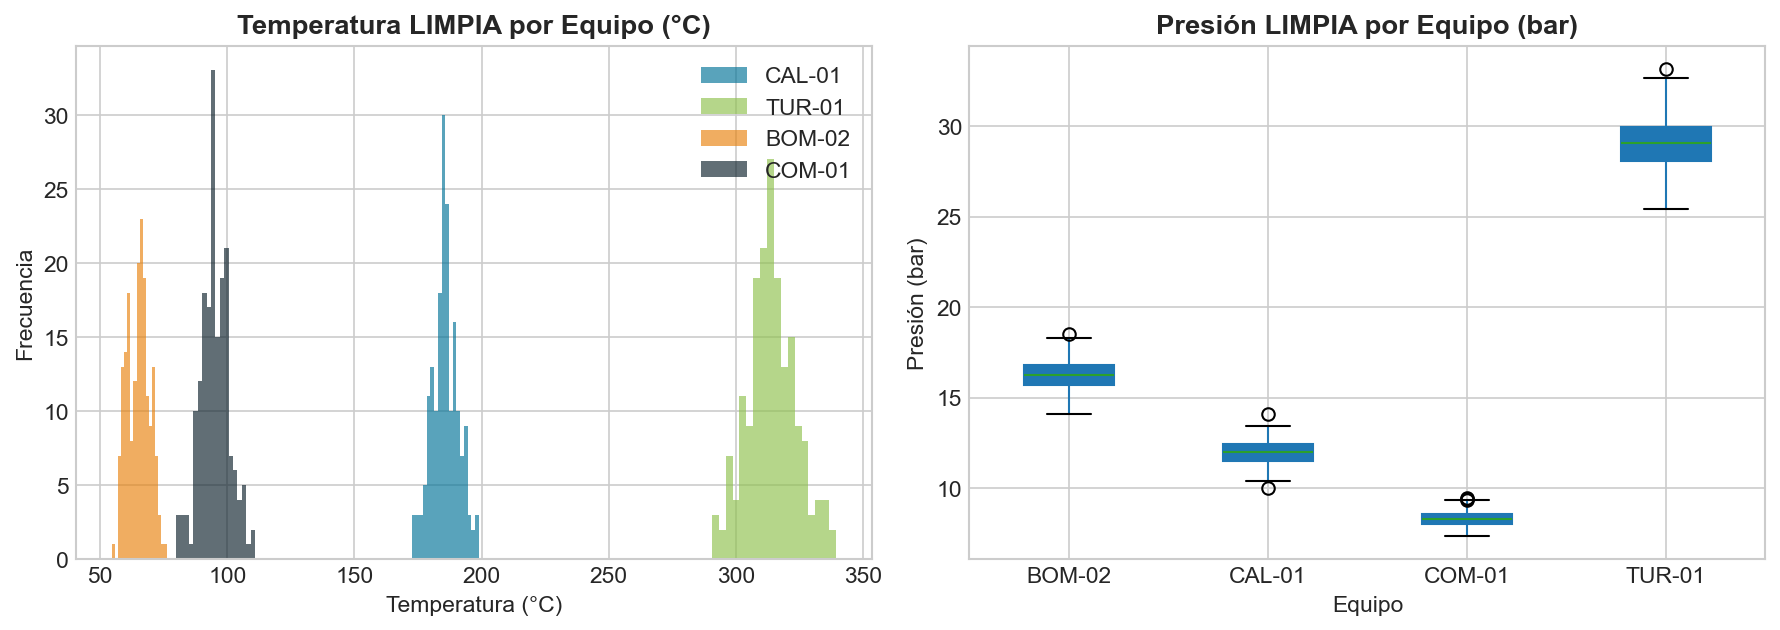

In [4]:
# 4. Pipeline limpio: deduplicar -> anular picos imposibles -> imputar por mediana de equipo
df_clean = df_raw.copy()

# 4.1 Eliminar duplicados exactos
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 4.2 Convertir lecturas físicamente imposibles a NaN para no distorsionar promedios
mask_temp_bad = (df_clean["temperatura_c"] > 500) | (df_clean["temperatura_c"] < 0)
mask_pres_bad = (df_clean["presion_bar"] < 0) | (df_clean["presion_bar"] > 60)
df_clean.loc[mask_temp_bad, "temperatura_c"] = np.nan
df_clean.loc[mask_pres_bad, "presion_bar"] = np.nan

# 4.3 Imputar con la mediana específica de cada equipo (robusta ante outliers)
for col in ["temperatura_c", "presion_bar"]:
    medianas_equipo = df_clean.groupby("equipo")[col].transform("median")
    df_clean[col] = df_clean[col].fillna(medianas_equipo)

print("Filas después de limpiar:", len(df_clean))
print("Total de nulos restantes:", int(df_clean.isnull().sum().sum()))
print("Rango limpio temperatura_c:", round(df_clean["temperatura_c"].min(), 1), "a", round(df_clean["temperatura_c"].max(), 1), "°C")
print("Rango limpio presion_bar  :", round(df_clean["presion_bar"].min(), 1), "a", round(df_clean["presion_bar"].max(), 1), "bar")

# Comparativa visual limpia por equipo
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for eq, col_c in zip(["CAL-01", "TUR-01", "BOM-02", "COM-01"], [PUNGO_BLUE, PUNGO_LIME, PUNGO_AMBER, PUNGO_NAVY]):
    sub = df_clean[df_clean["equipo"] == eq]
    axes[0].hist(sub["temperatura_c"], bins=18, alpha=0.65, label=eq, color=col_c)
axes[0].set_title("Temperatura LIMPIA por Equipo (°C)")
axes[0].set_xlabel("Temperatura (°C)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

df_clean.boxplot(column="presion_bar", by="equipo", ax=axes[1], patch_artist=True)
axes[1].set_title("Presión LIMPIA por Equipo (bar)")
axes[1].set_xlabel("Equipo")
axes[1].set_ylabel("Presión (bar)")
plt.suptitle("")
plt.tight_layout()
plt.show()

## Paso 5 — Columnas Calculadas, `.groupby()` (Tablas Dinámicas) y Datos CCPP
Una vez limpios los datos, creamos columnas derivadas (como costo energético) y resumimos en segundos por equipo y turno — el equivalente supercargado de las Tablas Dinámicas de Excel.

=== TABLA DINÁMICA: EQUIPO × TURNO ===
               registros  temp_media_c  vib_media_mms  costo_promedio_usd
equipo turno                                                             
BOM-02 Manana         60         63.52           2.43               50.21
       Noche          60         66.76           3.28               51.43
       Tarde          60         64.84           2.86               50.47
CAL-01 Manana         60        184.88           1.97               92.69
       Noche          60        186.63           2.57               92.14
       Tarde          60        185.13           2.24               93.34
COM-01 Manana         60         93.66           2.76               72.93
       Noche          60         97.38           3.43               73.49
       Tarde          60         94.10           3.09               73.55
TUR-01 Manana         60        312.57           2.94              430.92
       Noche          60        316.05           3.51              432.94

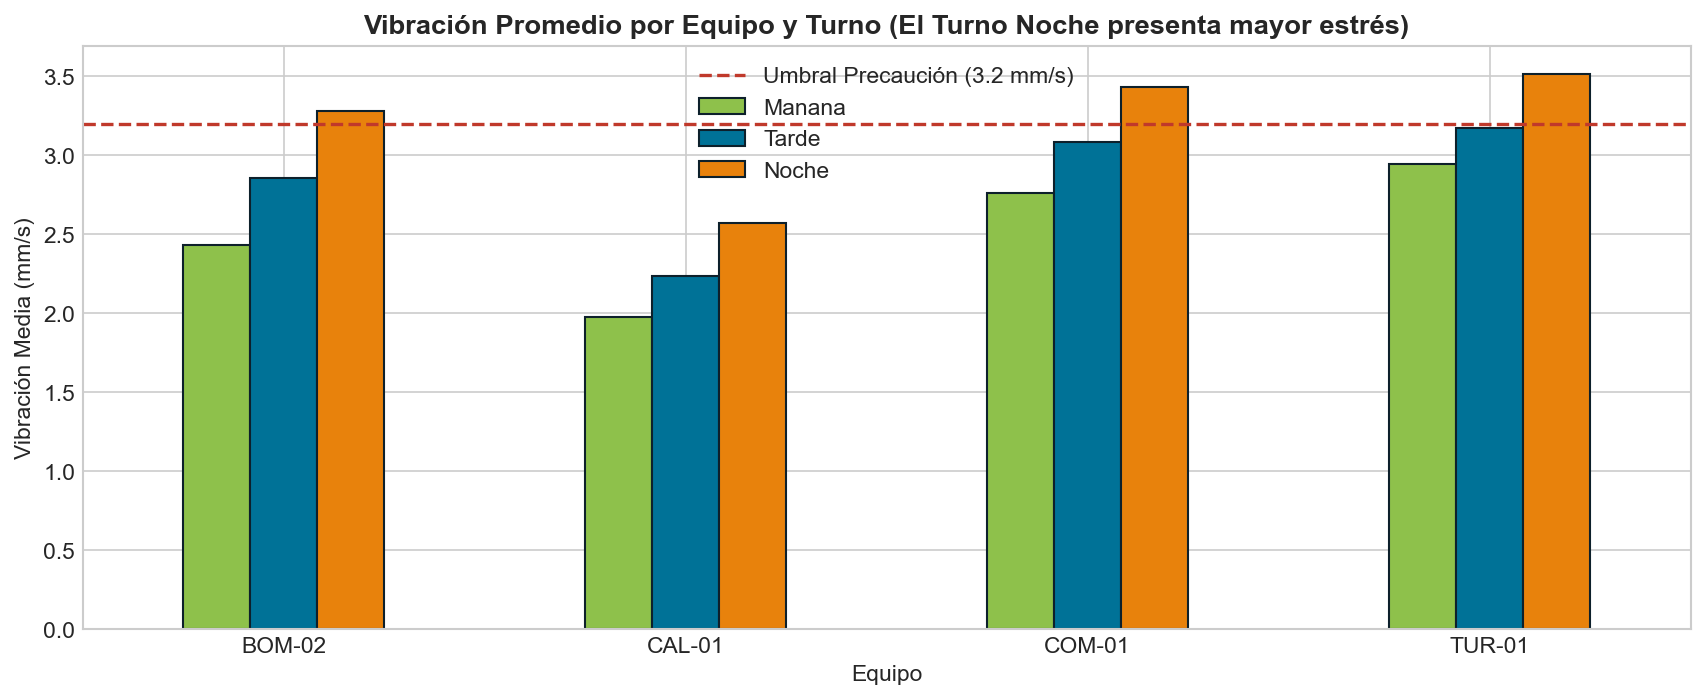


Dataset CCPP listo para Módulo 5: 9,568 filas × 5 columnas
            AT        V       AP       RH       PE
count  9568.00  9568.00  9568.00  9568.00  9568.00
mean     19.65    54.31  1013.26    73.31   454.37
std       7.45    12.71     5.94    14.60    17.07
min       1.81    25.36   992.89    25.56   420.26
25%      13.51    41.74  1009.10    63.33   439.75
50%      20.34    52.08  1012.94    74.97   451.55
75%      25.72    66.54  1017.26    84.83   468.43
max      37.11    81.56  1033.30   100.16   495.76


In [5]:
# 5. Columnas calculadas, tabla dinámica .groupby() y conexión con CCPP (9,568 filas)
df_clean["costo_energia_4h_usd"] = (df_clean["potencia_kw"] * 4.0 * 0.11).round(2)

resumen_turno = (
    df_clean.groupby(["equipo", "turno"])
    .agg(
        registros=("temperatura_c", "count"),
        temp_media_c=("temperatura_c", "mean"),
        vib_media_mms=("vibracion_mms", "mean"),
        costo_promedio_usd=("costo_energia_4h_usd", "mean"),
    )
    .round(2)
)
print("=== TABLA DINÁMICA: EQUIPO × TURNO ===")
print(resumen_turno)

# Gráfico de vibración promedio por turno y equipo
piv_vib = df_clean.pivot_table(index="equipo", columns="turno", values="vibracion_mms", aggfunc="mean")[["Manana", "Tarde", "Noche"]]
ax = piv_vib.plot(kind="bar", figsize=(11.5, 4.8), color=[PUNGO_LIME, PUNGO_BLUE, PUNGO_AMBER], edgecolor=PUNGO_NAVY)
ax.axhline(3.2, color=PUNGO_RED, linestyle="--", linewidth=1.6, label="Umbral Precaución (3.2 mm/s)")
ax.set_title("Vibración Promedio por Equipo y Turno (El Turno Noche presenta mayor estrés)")
ax.set_ylabel("Vibración Media (mm/s)")
ax.set_xlabel("Equipo")
ax.tick_params(axis="x", rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

# Carga y verificación rápida del dataset CCPP para el Módulo 5
df_ccpp = pd.read_csv(URL_CCPP)
print(f"\nDataset CCPP listo para Módulo 5: {df_ccpp.shape[0]:,} filas × {df_ccpp.shape[1]} columnas")
print(df_ccpp.describe().round(2))

## Paso 6 — Error Lab 04: `KeyError` en Columnas de Pandas
Uno de los errores más frecuentes al empezar con Pandas es escribir una columna con mayúscula o un espacio extra (por ejemplo `Temperatura_C` en vez de `temperatura_c`).

In [6]:
# 6. Error Lab 04: KeyError por escribir mal el nombre de una columna
try:
    promedio_mal = df_clean["Temperatura_C"].mean()
except KeyError as err:
    print("Error capturado -> KeyError: la columna", err, "no existe.")
    print("Columnas exactas disponibles:", list(df_clean.columns))
    print(f"Solución -> df_clean['temperatura_c'].mean() = {df_clean['temperatura_c'].mean():.2f} °C")

Error capturado -> KeyError: la columna 'Temperatura_C' no existe.
Columnas exactas disponibles: ['timestamp', 'equipo', 'turno', 'temperatura_c', 'presion_bar', 'flujo_m3h', 'potencia_kw', 'vibracion_mms', 'estado_operacion', 'costo_energia_4h_usd']
Solución -> df_clean['temperatura_c'].mean() = 164.94 °C


## Paso 7 — Tu Turno (Ejercicios Módulo 4)
1. **Reto 4.1:** Usando `df_ccpp` (9,568 filas), compara la generación eléctrica promedio `PE` (MW) en días calurosos (`AT > 30.0` °C) frente a días frescos (`AT < 15.0` °C). ¿Cuántos MW se pierden cuando sube la temperatura ambiente?

In [7]:
# Solución verificada — Tu Turno Módulo 4
calurosos = df_ccpp[df_ccpp["AT"] > 30.0]
frescos = df_ccpp[df_ccpp["AT"] < 15.0]

pe_calor = calurosos["PE"].mean()
pe_fresco = frescos["PE"].mean()
diferencia_mw = pe_fresco - pe_calor

print(f"Días frescos  (AT < 15°C, n={len(frescos):,}): PE promedio = {pe_fresco:.2f} MW")
print(f"Días calurosos (AT > 30°C, n={len(calurosos):,}): PE promedio = {pe_calor:.2f} MW")
print(f"Brecha térmica física: {diferencia_mw:.2f} MW menos en días calurosos")

Días frescos  (AT < 15°C, n=3,069): PE promedio = 474.65 MW
Días calurosos (AT > 30°C, n=733): PE promedio = 432.99 MW
Brecha térmica física: 41.66 MW menos en días calurosos
